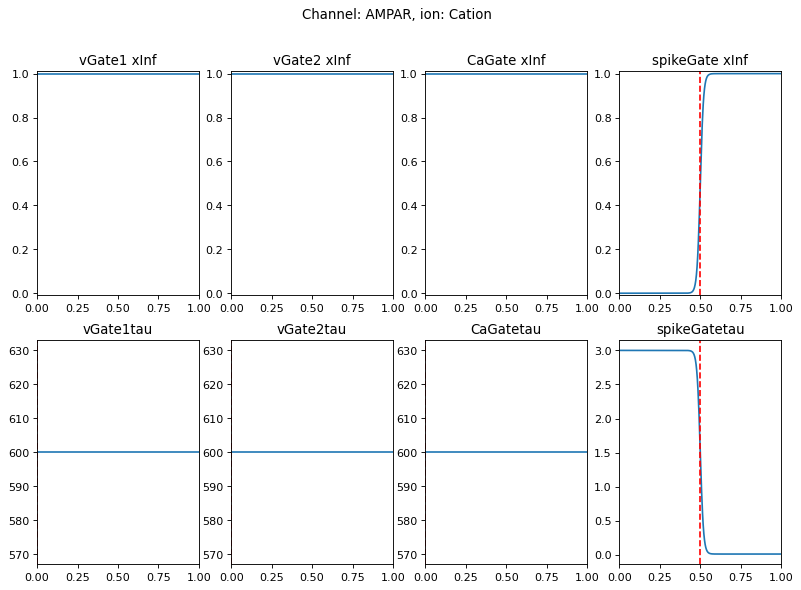

In [2]:
import numpy as np
import matplotlib.pyplot as plt

#we use inverse slope, 1/k, whereas most of the literature uses k. This is because we want to avoid division in the sigmoid function
def genGate(vHalf,vKi,tau0,tau1,th,tkInv,x0=0.0,exponent=1,minOpenness=0):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,"th":th,"tkInv":tkInv,"exponent":exponent,"minOpenness":minOpenness}

def genOpenGate():
    return genGate(-1000,1000,100,1000,0,0,x0=1)

def genSynapseGate(xt1,TS):
    xt0 = TS
    xt1 = xt1-xt0
    return genGate(0.5,100,xt0,xt1,0.5,-100)


def genDefaultPlasticSynapseData(gain):
    return {
        "efficacy": 0, #p, unitless
        "conductanceGain": gain, #
        "rate": 0.05, #ms
        "gammaP": 0.12, #p per ms
        "gammaD": 0.078, #p per ms
        "thetaP": 0.68, #Ca mol/L
        "thetaD": 0.33, #Ca mol/L
    }

def genAMPA(TS):
    #for the synapses to work properly you need to know TS
    #This lets the conductance go instantly from 0 to 1
    #I wonder if this will cause instability?
    #If this doesnt work I'll have to implement a more expensive second order ODE
    gain = 10
    AMPA = {"name":"AMPAR",
                "ion":"Cation",
            "Erev": 0,
            "conductance": gain,
            "current":0,
            "CaCurrent": 0,
            "gates":{
            "vGate1":genOpenGate(),
            "vGate2":genOpenGate(),
            "CaGate":genOpenGate(),
            "spikeGate":genSynapseGate(3,TS)}}
    for key,val in genDefaultPlasticSynapseData(gain).items():
        AMPA[key] = val
    return AMPA


def sigmoid(z,h,kInv,minOp):
    return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))

def examineGate(gateInfo,valRange,gateName,ax=None):
    gRange = [min(valRange),max(valRange)]
    vH,vK = gateInfo["vHalf"],gateInfo["vKi"]
    tau0,tau1,th,tkInv = gateInfo["tau0"],gateInfo["tau1"],gateInfo["th"],gateInfo["tkInv"]
    minOp = gateInfo["minOpenness"]
    

    xInf = sigmoid(valRange,vH,vK,minOp)
    tau = tau0 + tau1*sigmoid(valRange,th,tkInv,0)
    if ax == None:
        fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100)
    else:
        ax[0].plot(valRange,xInf)
        ax[0].axvline(vH,color="r",linestyle="--")
        ax[0].set_title(f"{gateName} xInf")
        ax[0].set_xlim(gRange)
        #x[0].set_ylabel("Gate opening")
        ax[0].set_ylim(-0.01,1.01)

        ax[1].plot(valRange,tau)
        ax[1].axvline(th,color="r",linestyle="--")
        ax[1].set_title(f"{gateName}tau")
        #ax[1].set_ylabel("Time constant (ms)")
        ax[1].set_xlim(gRange)
    
    return xInf

def examineChannel(channel,s0=-100,s1=100):
    fig,ax = plt.subplots(2,4,figsize=(12,8), dpi=80)
    fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    valRange = np.linspace(s0,s1,501)
    netOpening = 1
    for i,(gate,gateData) in enumerate(channel["gates"].items()):
        exponent = gateData["exponent"]
        xInf = examineGate(gateData,valRange,gate,[ax[0,i],ax[1,i]])
        netOpening *= xInf**exponent

    # fig,ax = plt.subplots(1,1,dpi=90,figsize=[7,4])
    # ax.plot(valRange,netOpening)


TS=0.01
amp = genAMPA(TS)

examineChannel(amp,0,1)

In [3]:
# STNgates = {
    
#     "m":genOtsukaGate(-40,-1/8,0.2,3,0,-53,0,-1/7,0,exponent=3,x0=0.104),
#     "h":genOtsukaGate(-45.5,1/6.4,0,24.5,1,-50,-50,-1/15,-1/16,x0=0.861),

#     "n":genOtsukaGate(-41,-1/14,0,11,1,-40,-40,-1/40,-1/50,exponent=4,x0=0.239),

#     "a":genOtsukaGate(-45,-1/14.7,1,1,0,-40,0,-1/0.5,0,exponent=2,x0=0.303),
#     "b":genOtsukaGate(-90,1/7.5,0,200,1,-60,-40,-1/30,-1/10,x0=0.012),

#     "p":genOtsukaGate(-56,-1/6.7,5,0.33,1,-27,-102,-1/10,-1/15,exponent=2,x0=0.455),
#     "q":genOtsukaGate(-85,1/5.8,0,400,1,-50,-50,-1/15,-1/16,x0=0.008),
    
#     "c":genOtsukaGate(-30.6,-1/5,45,10,1,-27,-50,-1/20,-1/15,exponent=2,x0=0.02),
#     "d1":genOtsukaGate(-60,7.5,400,500,1,-40,-20,-1/15,-1/20,x0=0.406),
    
#     "r":genOtsukaGate(1.7e-4,-1/8e-5,2,0,0,0,0,0,0,CaDependent=True,x0=0.11), #Ca dependent
#     "d2":genOtsukaGate(1e-4,1/2e-5,130,0,0,0,0,0,0,CaDependent=True,x0=0.992), #Ca dependent
# }


# KvOts,K,n,4,-41,-14,1,11,1,-40,-40,-40,50,1,0,3,Otsuka
# NavOts,Na,m,3,-40,-8,0.2,3,0,-53,0,-0.7,1,22.29,0,3,Otsuka
# NavOts,Na,h,1,-45.5,6.4,0.1,24.5,1,-50,-50,-15,16,22.29,0,3,Otsuka
# KAOts,K,a,2,-45,-14.7,1,1,0,-40,0,-0.5,0,633.5,0,3,Otsuka
# KAOts,K,b,1,-90,7.5,0,200,1,-60,-40,-30,10,633.5,0,3,Otsuka
# CaTOts,Ca,p,2,-56,-6.7,5,0.33,1,-27,-102,-10,15,585.01,0,3,Otsuka
# CaTOts,Ca,q,1,-85,5.8,0,400,1,-50,-50,-15,16,585.01,0,3,Otsuka

# from telnetlib import EC
# from sympy import E


def genOtsukaGateOld(vHalf,vKi,tau0,tau1,tau2,th1,tkInv1,th2,thInv2,x0=0.0,exponent=1,minOpenness=0,CaDependent=False):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,
            "tau2":tau2,"th1":th1,"tkInv1":tkInv1,"th2":th2,"tkInv2":thInv2,
            "exponent":exponent,"minOpenness":minOpenness,"CaDependent":CaDependent}

def genOtsukaGate(vHalf,vKi,tau0,tau1,tau2,th1,th2,tkInv1,thInv2,x0=0.0,exponent=1,minOpenness=0,CaDependent=False):
    tau2 = 1 #always set it to 1, because either second exponential has some value depeding on v, or else its 1
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,
            "tau2":tau2,"th1":th1,"tkInv1":tkInv1,"th2":th2,"tkInv2":thInv2,
            "exponent":exponent,"minOpenness":minOpenness,"CaDependent":CaDependent}

mod=0.0
STNgates = {
    
    "m":genOtsukaGate(-40,-1/8,0.2,3,0,-53,0,-1/0.7,0,exponent=3,x0=0.104),
    "h":genOtsukaGate(-45.5,1/6.4,0,24.5,1,-50,-50,-1/15,1/16,x0=0.861),

    "n":genOtsukaGate(-41,-1/14,0,11,1,-40,-40,-1/40,1/50,exponent=4,x0=0.239),

    "a":genOtsukaGate(-45,-1/14.7,1,1,0,-40,0,-1/0.5,0,exponent=2,x0=0.303),
    "b":genOtsukaGate(-90,1/7.5,0,200,1,-60,-40,-1/30,1/10,x0=0.012),

    "p":genOtsukaGate(-56,-1/6.7,5,0.33,1,-27,-102,-1/10,1/15,exponent=2,x0=0.455),
    "q":genOtsukaGate(-85,1/5.8,0,400,1,-50,-50,-1/15,1/16,x0=0.008),

    "c":genOtsukaGate(-30.6,-1/5,45,10,1,-27,-50,-1/20,1/15,exponent=2,x0=0.02),
    "d1":genOtsukaGate(-60,1/7.5,400,500,1,-40,-20,-1/15,1/20,x0=0.406),
    
    "r":genOtsukaGate(1.7e-4,-1/8e-5,2,0,0,0,0,0,0,CaDependent=True,x0=0.11), #Ca dependent, i think it should be 1.7e-4 and -1/8e-5 #Otsuka has 0.17,-1/0.08
    "d2":genOtsukaGate(1e-4,1/2e-5,130,0,0,0,0,0,0,CaDependent=True,x0=0.992), #Ca dependent, i think it should be 1e-4, 1/2e-5 #Otsuka has 0.1,1/0.02

    # "r":genOtsukaGate(0.17,-1/0.08,2,0,0,0,0,0,0,CaDependent=True,x0=0.11), #Ca dependent, i think it should be 1.7e-4 and -1/8e-5 #Otsuka has 0.17,-1/0.08
    # "d2":genOtsukaGate(0.1,1/0.02,130,0,0,0,0,0,0,CaDependent=True,x0=0.992), #Ca dependent, i think it should be 1e-4, 1/2e-5 #Otsuka has 0.1,1/0.02
}




ENa = 60
EK = -90
ECa = 120
ELeak = -60

otsukaNa = {"name":"NavOts",
              "ion":"Na",
                "Erev": ENa,
                "conductance": 49,
                "CaCurrent": 0,
                "gates":{
                 "m":STNgates["m"],
                 "h":STNgates["h"]}
                }

otsukaKdr = {"name":"KvOts",
           "ion":"K",
            "Erev": EK,
            "conductance": 57,
            "CaCurrent": 0,
            "gates":{
                "n":STNgates["n"]}
            }

otsukaAHP = {"name":"KAHPOts",
            "ion":"K",
            "Erev": EK,
            "conductance": 0.7,
            "CaCurrent": 0,
            "gates":{
                "r":STNgates["r"],}
            }

otsukaA = {"name":"KAOts",
              "ion":"K",
                "Erev": EK,
                "conductance": 5,
                "CaCurrent": 0,
                "gates":{
                 "a":STNgates["a"],
                 "b":STNgates["b"]}
                }

otsukaCaT = {"name":"CaTOts",
            "ion":"Ca",
            "Erev": ECa,
            "conductance": 5,
            "CaCurrent": 1,
            "gates":{
                "p":STNgates["p"],
                "q":STNgates["q"]}
            }
otsukaCaL = {"name":"CaLOts",
            "ion":"Ca",
            "Erev": ECa,
            "conductance": 15,
            "CaCurrent": 1,
            "gates":{
                "c":STNgates["c"],
                "d1":STNgates["d1"],
                "d2":STNgates["d2"]}
            }

ostukaLeakChannel = {"name":"leak",
            "ion":"all",
           "Erev": ELeak,
           "conductance": 0.29,
           "current":0,
           "CaCurrent": 0,
           "gates":{
           "vGate1":genOtsukaGate(-1000,-0.1,2,0,0,0,0,0,0,x0=1),}}

from copy import deepcopy
STNcurrents =[deepcopy(x) for x in [otsukaNa,otsukaKdr,otsukaAHP,otsukaA,otsukaCaT,otsukaCaL,ostukaLeakChannel]]

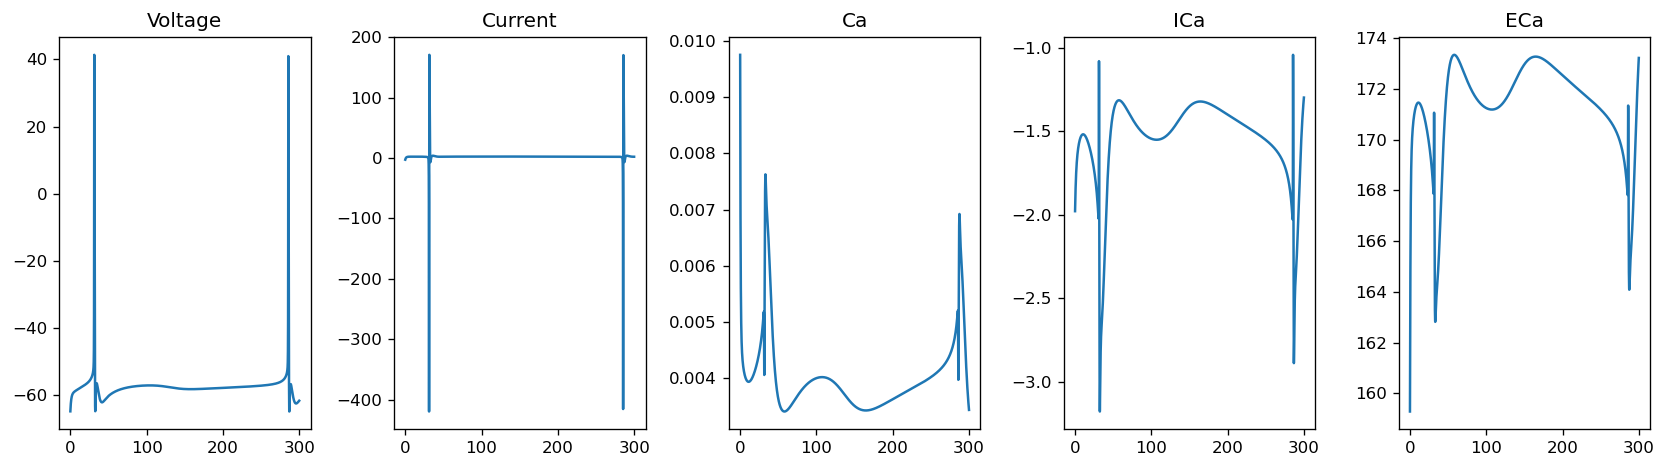

In [34]:

def sigmoid(z,h,kInv,minOp):
    return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))

# def otsukaTauSigmoid(v,tau0,tau1,tau2,theta0,theta1,kInv0,kInv1):
#     return tau0 + tau1/( 1-tau2 + np.exp(-(v-theta0)*kInv0) + tau2*np.exp(-(v-theta1)*kInv1) )

def otsukaTauSigmoid(v,tau0,tau1,tau2,theta0,theta1,kInv0,kInv1):
    return tau0 + tau1/(np.exp(-(v-theta0)*kInv0) + tau2*np.exp(-(v-theta1)*kInv1) )


def otsukaSolveGate(gateData,V,TS):
    xInf = sigmoid(V,gateData["vHalf"],-gateData["vKi"],0) #rather interesting that the otsuka paper requires the exponential to be opposite sign, why not just be consistent?
    xTau = otsukaTauSigmoid(V,gateData["tau0"],gateData["tau1"], gateData["tau2"], gateData["th1"],gateData["th2"],gateData["tkInv1"],gateData["tkInv2"])
    x = gateData["x"]
    #return gateData["x"] + TS*(xInf-gateData["x"])/xTau
    return (xTau*x + TS*xInf)/(xTau+TS)

eCa = 377.1/1000
#kCa = .2/eCa
kCa = 2 #Ca removal rate in 
F = 96485
alpha = 1/(2*F) #2 because Ca is divalent

def solveSingleNeuron(channelList,runTime,TS,bias = 0,stimTimes=None,stimVal=None):
    V,I,ICa,Ca = -65,0,0,1e-5
    records = {x:[] for x in ["voltages","Ca","I","ICa","ECa"] + [y["name"] for y in channelList]}
    timeVec = np.arange(0,runTime,TS)
    for i,t in enumerate(timeVec):
        I,ICa =0,0
        ECa = 13.05 * np.log(2.0 / Ca) 
        for channel in channelList:
            cond = channel["conductance"]
            Erev = channel["Erev"]
            caCurr = channel["CaCurrent"]
            
            # if caCurr:
            #     Erev = ECa
            
            gatingVal = 1
            for g,data in channel["gates"].items():
                gatingVal *= (data["x"]**data["exponent"])
            
            I0 = cond*gatingVal*(V-Erev)
            I += I0
            if caCurr:
                ICa+=I0

            records[channel["name"]].append(I0)

            for g,data in channel["gates"].items():
                if data["CaDependent"]:
                    ip = Ca
                else:
                    ip = V
                channel["gates"][g]["x"] = otsukaSolveGate(data,ip,TS)

        #dCa = eCa*ICa/(2*F) # -eCa*kCa*Ca
        #eCa*( (ICa/(2*F)) - kCa*Ca)
        dCa = -ICa*alpha - kCa*Ca #i think there should be an additional term to account for ca pumping/ transport/ homeostasis, check that rubin paper 
        Ca+=TS*dCa 
        if stimTimes is not None:
            if stimTimes[0]<t<stimTimes[1]:
                I+=stimVal

        V-=TS*(I+bias)
        records["voltages"].append(V)
        records["Ca"].append(Ca)
        records["I"].append(I)
        records["ICa"].append(ICa)
        records["ECa"].append(ECa)

        if abs(I)>5e3:
            print(f"Breaking")
            break

    records["timeVec"] = np.linspace(0,i*TS,i+1)
    records["voltages"] = np.array(records["voltages"])
    records["Ca"] = 1e3*np.array(records["Ca"])
    for key in channelList:
        records[key["name"]] = np.array(records[key["name"]])
        
    return records

from copy import deepcopy
STNcurrents =[deepcopy(x) for x in [otsukaNa,otsukaKdr,otsukaAHP,otsukaA,otsukaCaT,otsukaCaL,ostukaLeakChannel]]

#STNcurrents =[deepcopy(x) for x in [otsukaNa,otsukaKdr,ostukaLeakChannel]]

runTime = 300
recs = solveSingleNeuron(STNcurrents,runTime,0.025,bias=-2.5,stimTimes = [100,130],stimVal = 0)

fig,ax = plt.subplots(1,5,figsize=(14,4),dpi=120)
ax[0].plot(recs["timeVec"],recs["voltages"])
ax[0].set_title("Voltage")
ax[1].plot(recs["timeVec"],recs["I"])
ax[1].set_title("Current")
ax[2].plot(recs["timeVec"],recs["Ca"])
ax[2].set_title("Ca")
ax[3].plot(recs["timeVec"],recs["ICa"])
ax[3].set_title("ICa")
ax[4].plot(recs["timeVec"],recs["ECa"])
ax[4].set_title("ECa")
plt.tight_layout()

(0.0, 70.0)

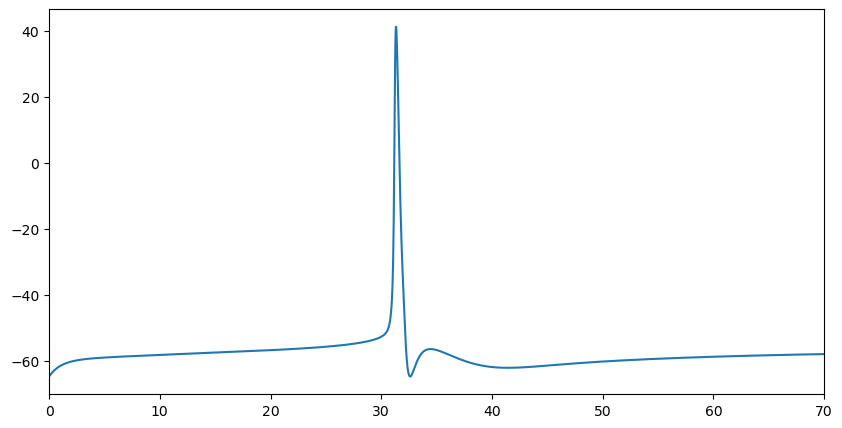

In [87]:
t,v = recs["timeVec"],recs["voltages"]
fig,ax = plt.subplots(1,1,figsize=(10,5),dpi=100)
ax.plot(t,v)
ax.set_xlim(0,70)

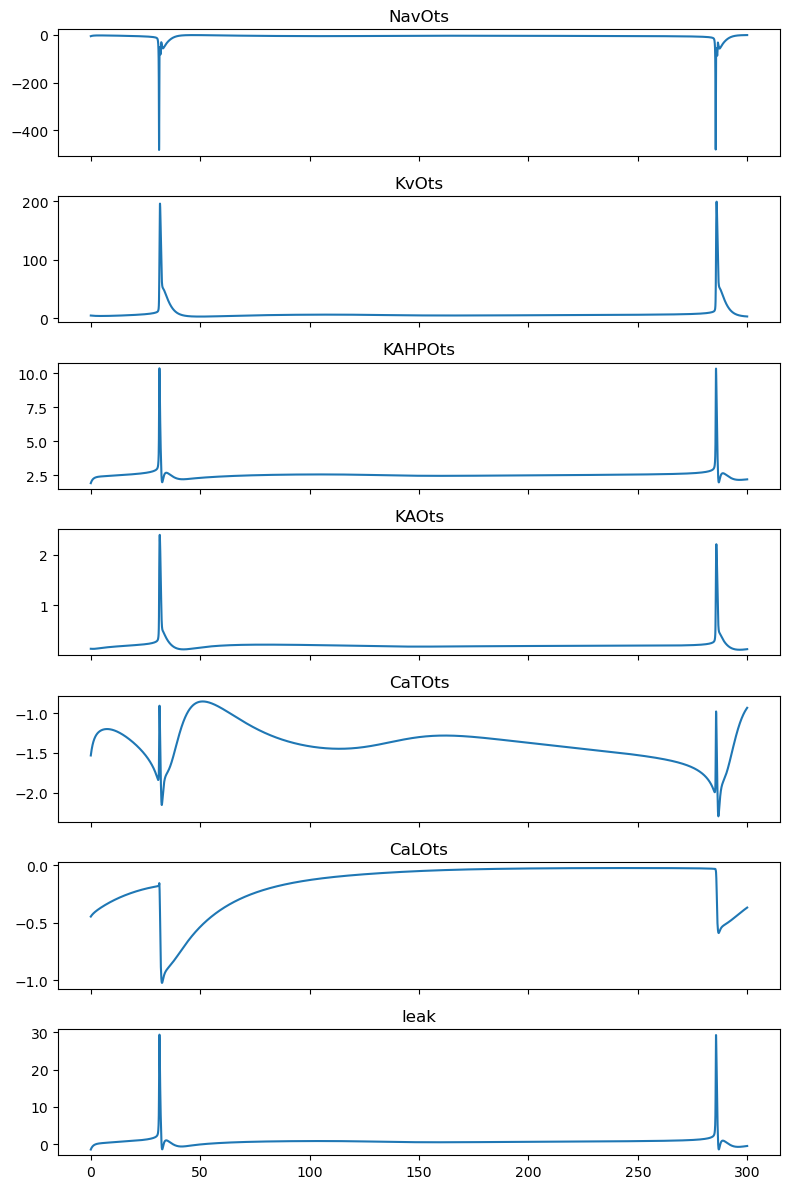

In [35]:
fig,ax = plt.subplots(len(STNcurrents),1,figsize=(8,12),dpi=100,sharex=True)
for i,channel in enumerate(STNcurrents):
    ax[i].plot(recs["timeVec"],recs[channel["name"]])
    ax[i].set_title(channel["name"])

plt.tight_layout()

In [8]:
def otsukaTauSigmoid(v,tau0,tau1,tau2,theta0,theta1,kInv0,kInv1):
    return tau0 + tau1/(np.exp(-(v-theta0)*kInv0) + tau2*np.exp(-(v-theta1)*kInv1) )


def otsukaSolveGate(gateData,V,TS):
    xInf = sigmoid(V,gateData["vHalf"],-gateData["vKi"],0) #rather interesting that the otsuka paper requires the exponential to be opposite sign, why not just be consistent?
    xTau = otsukaTauSigmoid(V,gateData["tau0"],gateData["tau1"], gateData["tau2"], gateData["th1"],gateData["th2"],gateData["tkInv1"],gateData["tkInv2"])
    x = gateData["x"]
    #return gateData["x"] + TS*(xInf-gateData["x"])/xTau
    return (xTau*x + TS*xInf)/(xTau+TS)

def examineGateOtsuka(gateData,valRange,gateName,ax=None):
    xInf = sigmoid(valRange,gateData["vHalf"],-gateData["vKi"],0) #rather interesting that the otsuka paper requires the exponential to be opposite sign, why not just be consistent?
    xTau = otsukaTauSigmoid(valRange,gateData["tau0"],gateData["tau1"], gateData["tau2"], gateData["th1"],gateData["th2"],gateData["tkInv1"],gateData["tkInv2"])
    gRange = [min(valRange),max(valRange)]

    if ax is None:
        fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100)
    
    ax[0].plot(valRange,xInf)
    ax[0].axvline(gateData["vHalf"],color="r",linestyle="--")
    ax[0].set_title(f"{gateName} xInf")
    ax[0].set_xlim(gRange)
    #x[0].set_ylabel("Gate opening")
    ax[0].set_ylim(-0.01,1.01)

    ax[1].plot(valRange,xTau)
    ax[1].axvline(gateData["th1"],color="r",linestyle="--")
    ax[1].set_title(f"{gateName}tau")
    #ax[1].set_ylabel("Time constant (ms)")
    ax[1].set_xlim(gRange)
    
    return xInf

def examineChannelOtsuka(channel,ax=None):
    nSamples = 101
    if ax is None:
        fig,ax = plt.subplots(3,3,figsize=(12,8), dpi=80)
        fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    gateOpening = np.ones([nSamples])
    i=0
    valRange = np.linspace(-100,100,nSamples)
    for (gate,gateData) in channel["gates"].items():
        if gateData["CaDependent"]:
            vr = np.linspace(0,1e-3,nSamples)
            xInf = examineGateOtsuka(gateData,vr,gate,[ax[0,2],ax[1,2]])
        else:
            xInf = examineGateOtsuka(gateData,valRange,gate,[ax[0,i],ax[1,i]])
            exponent = gateData["exponent"]
            gateOpening *= xInf**exponent
            i+=1

    ax[2,0].plot(valRange,gateOpening)
    plt.tight_layout()

def genGate(vHalf,vKi,tau0,tau1,th,tkInv,x0=0.0,exponent=1,minOpenness=0):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,"th":th,"tkInv":tkInv,"exponent":exponent,"minOpenness":minOpenness}

def genOpenGate():
    return genGate(-1000,1000,100,1000,0,0,x0=1)

def genOtsukaGate(vHalf,vKi,tau0,tau1,tau2,th1,th2,tkInv1,thInv2,x0=0.0,exponent=1,minOpenness=0,CaDependent=False):
    tau2 = 1 #always set it to 1, because either second exponential has some value depeding on v, or else its 1
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,
            "tau2":tau2,"th1":th1,"tkInv1":tkInv1,"th2":th2,"tkInv2":thInv2,
            "exponent":exponent,"minOpenness":minOpenness,"CaDependent":CaDependent}

def translateOtsukaGate(gate,infSign=-1):
    newGate = genGate(vHalf=gate["vHalf"],
                      vKi = infSign*gate["vKi"], #otsuka uses the opposite sign on inf variables for some reason
                      tau0 = gate["tau0"],
                        tau1 = gate["tau1"],
                        th = gate["th1"],
                        tkInv = gate["tkInv1"],
                        x0 = gate["x"],
                        exponent = gate["exponent"],
                        minOpenness = gate["minOpenness"])
    return newGate
    
def translateOtsukaChannel(channel):
    newChannel = {"name":channel["name"],
            "ion":channel["ion"],
            "Erev": channel["Erev"],
            "conductance": channel["conductance"],
            "CaCurrent": channel["CaCurrent"],
            "gates":{
            "vGate1":genOpenGate(),
            "vGate2":genOpenGate(),
            "CaGate":genOpenGate(),
            "spikeGate":genOpenGate()}}
    
    vGateCount = 1
    for gate,data in channel["gates"].items():
        if vGateCount>3:
            raise ValueError("too many voltage gates")
        if data["CaDependent"]:
            newChannel["gates"]["CaGate"] = translateOtsukaGate(data)
        else:
            newChannel["gates"][f"vGate{vGateCount}"] = translateOtsukaGate(data)
            vGateCount+=1
            
    return newChannel


def examineGateNormal(gateData,valRange,gateName,ax=None):
    xInf = sigmoid(valRange,gateData["vHalf"],gateData["vKi"],gateData["minOpenness"]) #rather interesting that the otsuka paper requires the exponential to be opposite sign, why not just be consistent?
    xTau = gateData["tau0"] + gateData["tau1"]*sigmoid(valRange,gateData["th"],gateData["tkInv"],0)
    gRange = [min(valRange),max(valRange)]

    if ax is None:
        fig,ax = plt.subplots(2,1,figsize=(8,6), dpi=100)
    
    ax[0].plot(valRange,xInf,c="orange",ls="--")
    ax[0].axvline(gateData["vHalf"],color="g",linestyle="--")
    ax[0].set_title(f"{gateName} xInf")
    ax[0].set_xlim(gRange)
    #x[0].set_ylabel("Gate opening")
    ax[0].set_ylim(-0.01,1.01)

    ax[1].plot(valRange,xTau,c="orange",ls="--")
    ax[1].axvline(gateData["th"],color="g",linestyle="--")
    ax[1].set_title(f"{gateName}tau")
    #ax[1].set_ylabel("Time constant (ms)")
    ax[1].set_xlim(gRange)
    
    return xInf

def examineChannelNormal(channel,ax=None):
    nSamples = 101
    if ax is None:
        fig,ax = plt.subplots(3,3,figsize=(12,8), dpi=80)
        fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    gateOpening = np.ones([nSamples])
    for i,(gate,gateData) in enumerate(channel["gates"].items()):
        if gate != "spikeGate":
            if gate == "CaGate":
                vr = np.linspace(0,1e-3,nSamples)
                xInf = examineGateNormal(gateData,vr,gate,[ax[0,i],ax[1,i]])
            else:
                valRange = np.linspace(-100,100,nSamples)
                xInf = examineGateNormal(gateData,valRange,gate,[ax[0,i],ax[1,i]])
                exponent = gateData["exponent"]
                gateOpening *= xInf**exponent

    ax[2,0].plot(valRange,gateOpening,c="orange",ls="--")
    plt.tight_layout()

def createAndCompareChannel(channel):
    newChannel = translateOtsukaChannel(channel)

    fig,ax = plt.subplots(3,3,figsize=(12,8), dpi=80)
    fig.suptitle(f"Channel: {channel['name']}, ion: {channel['ion']}")
    examineChannelOtsuka(channel,ax)
    examineChannelNormal(newChannel,ax)

#createAndCompareChannel(otsukaNa)

#examineGate(STNgates["m"],np.linspace(-100,100,101),"m");
#examineChannelOtsuka(otsukaCaL)
# transNa = translateOtsukaChannel(otsukaNa)
# examineChannelNormal(transNa)
#examineGateNormal(translateOtsukaGate(otsukaNa["gates"]["m"]),np.linspace(-100,100,101),"m");

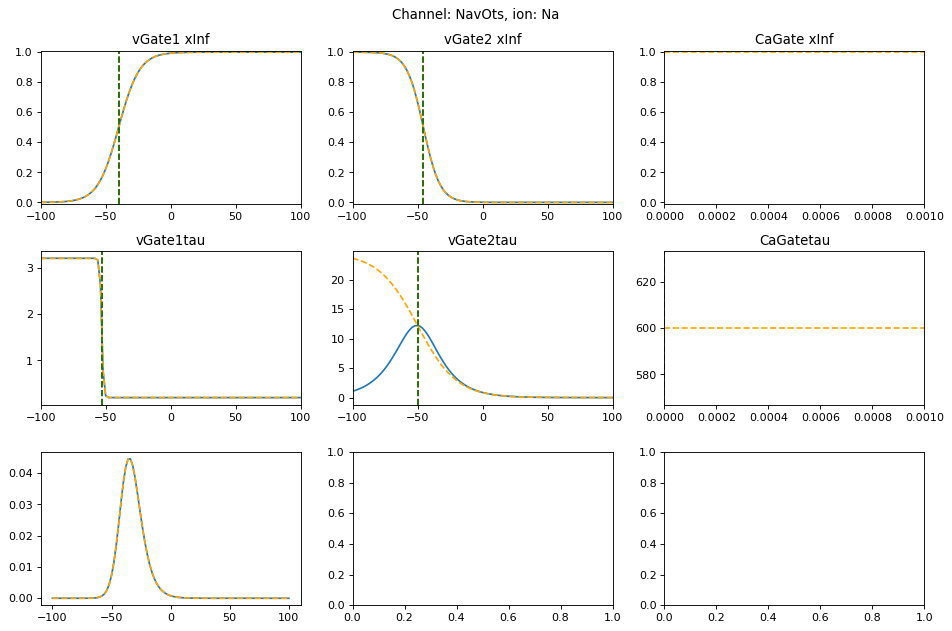

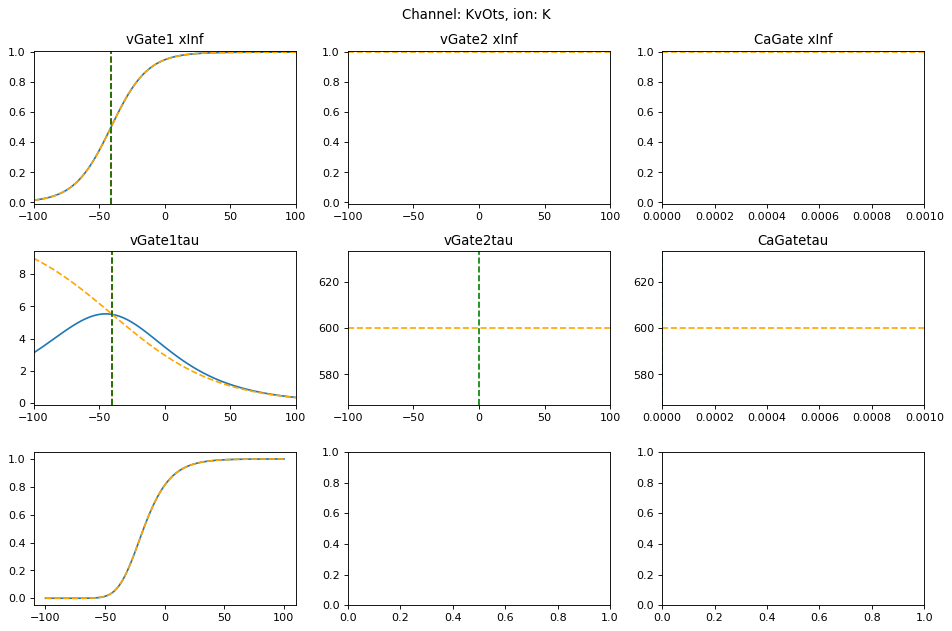

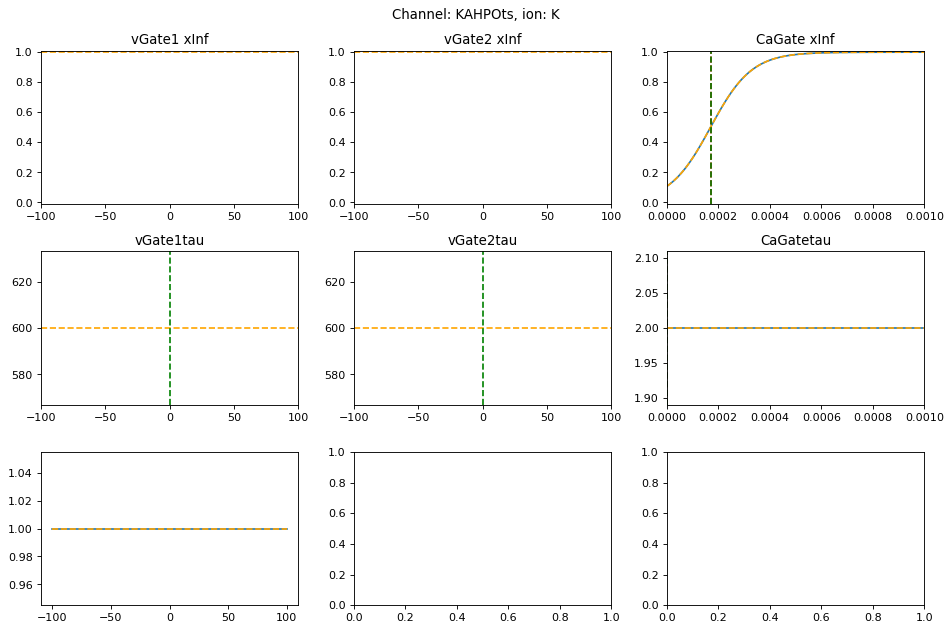

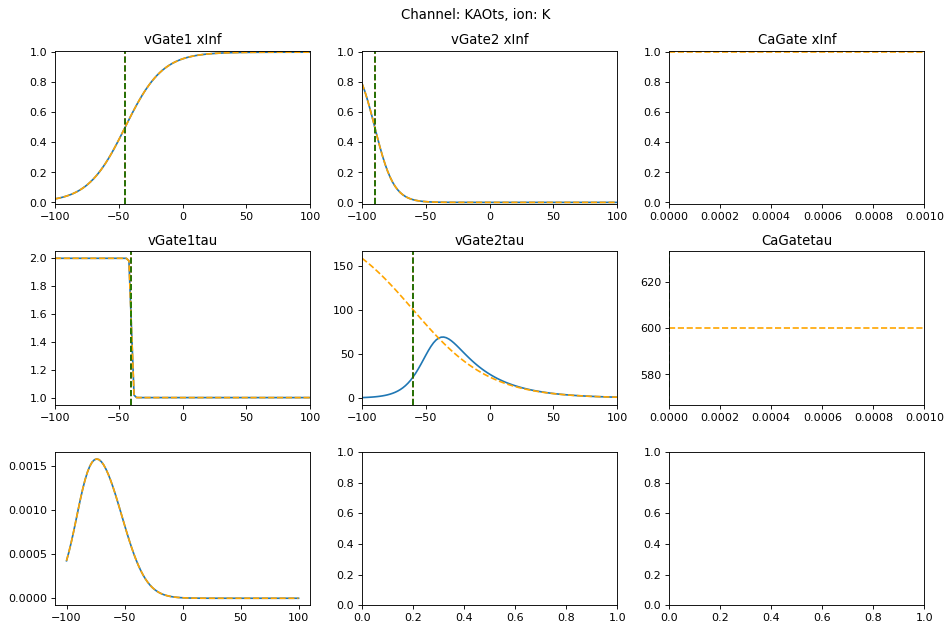

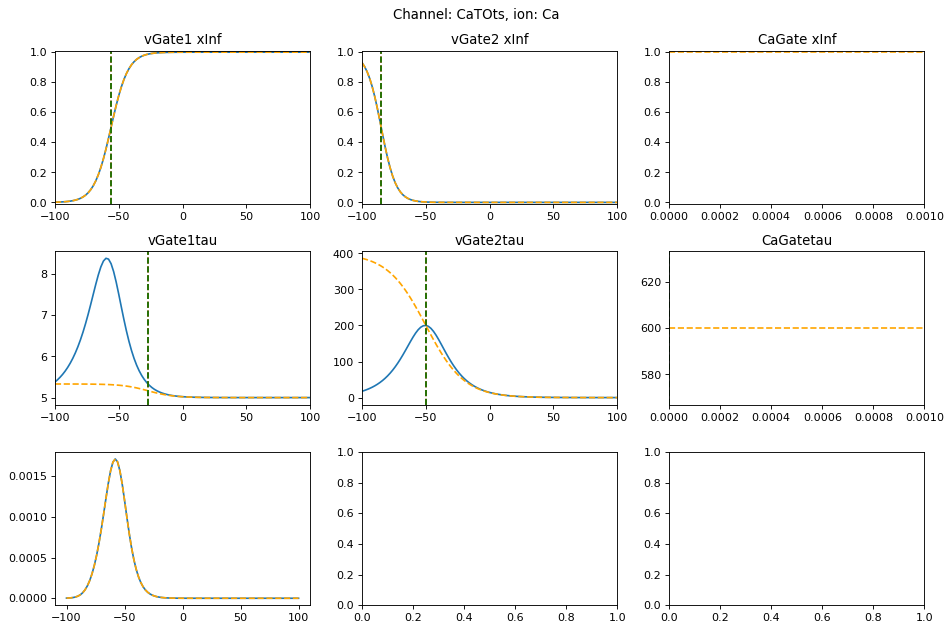

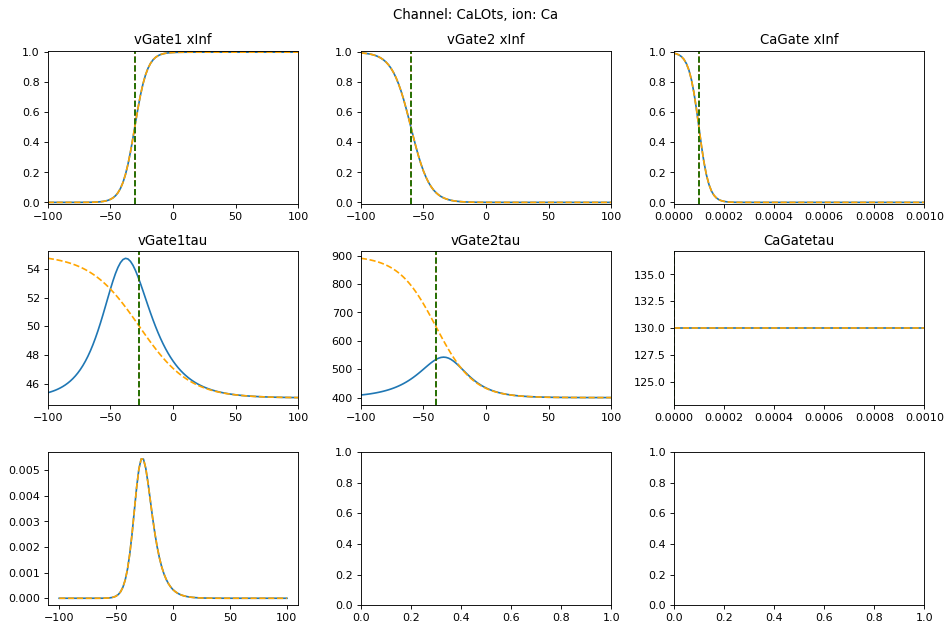

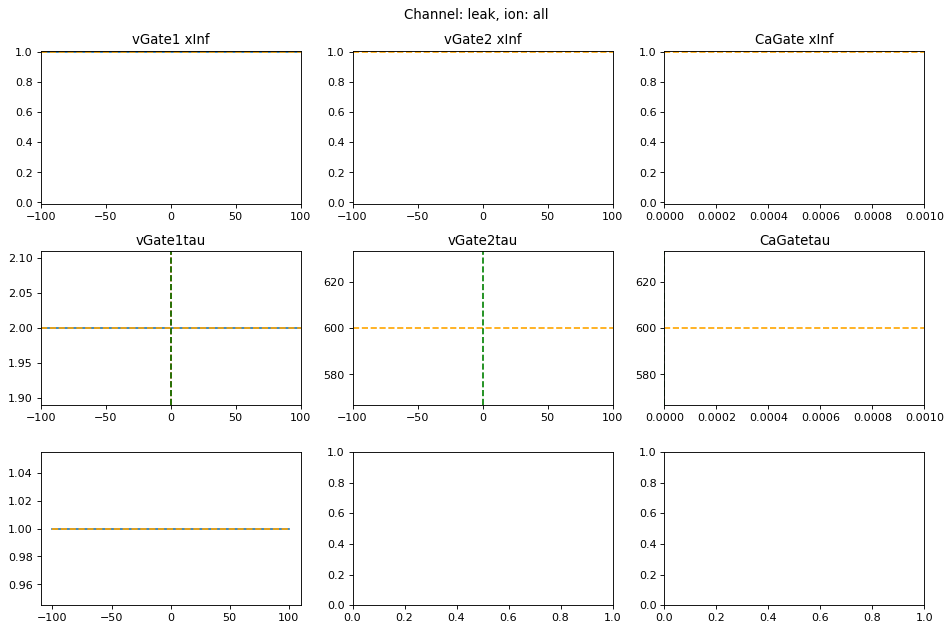

In [9]:
for channel in STNcurrents:
    createAndCompareChannel(channel)

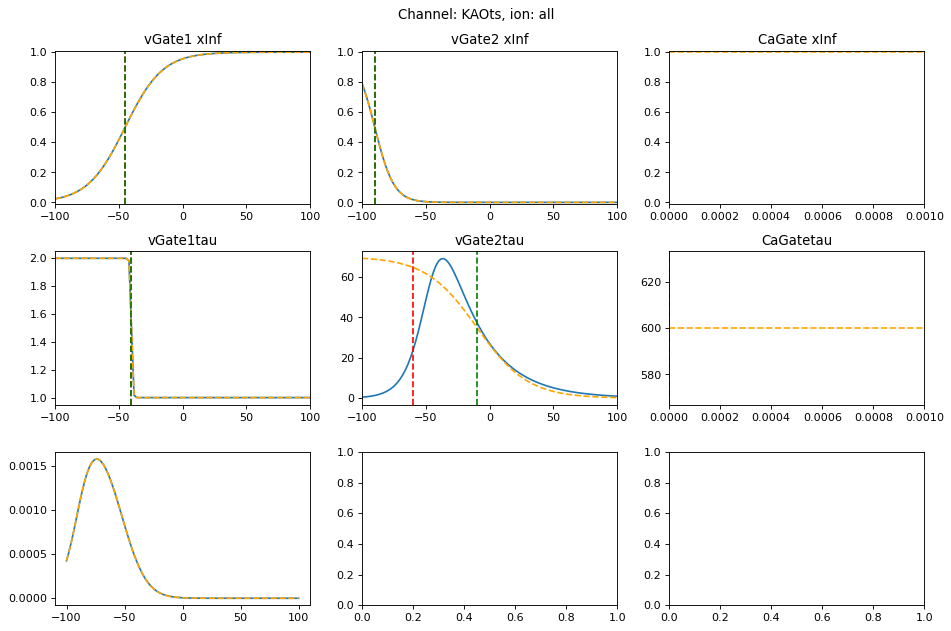

In [36]:
stnCurrentDict = {x["name"]:x for x in STNcurrents}
translatedCurrents = {name:translateOtsukaChannel(x) for name,x in stnCurrentDict.items()}

channelToChange = "KAOts"
# translatedCurrents[channelToChange]["gates"]["vGate1"]["tau1"] = 4
# translatedCurrents[channelToChange]["gates"]["vGate1"]["th"] = -47

translatedCurrents[channelToChange]["gates"]["vGate2"]["tau1"] = 70
translatedCurrents[channelToChange]["gates"]["vGate2"]["th"] = -10
translatedCurrents[channelToChange]["gates"]["vGate2"]["tkInv"] = -1/20

fig,ax = plt.subplots(3,3,figsize=(12,8), dpi=80)
fig.suptitle(f"Channel: {channelToChange}, ion: {channel['ion']}")
examineChannelOtsuka(stnCurrentDict[channelToChange],ax)
examineChannelNormal(translatedCurrents[channelToChange],ax)

In [27]:
translatedCurrents[channelToChange]["gates"]["vGate1"]

{'x': 0.4325358286915767,
 'vHalf': -56,
 'vKi': 0.14925373134328357,
 'tau0': 5,
 'tau1': 3,
 'th': -47,
 'tkInv': -0.1,
 'exponent': 2,
 'minOpenness': 0}

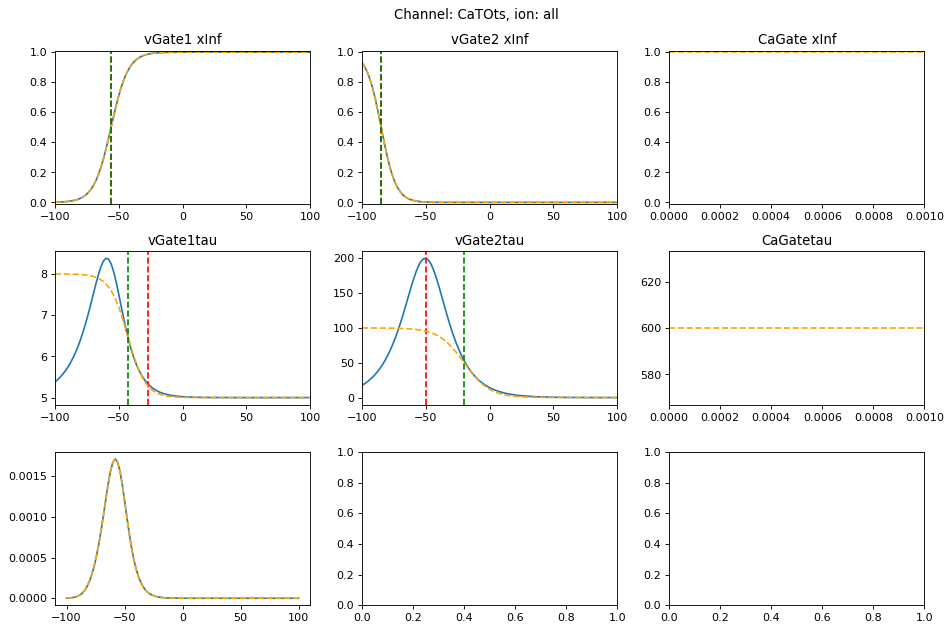

In [42]:
channelToChange = "CaTOts"
translatedCurrents[channelToChange]["gates"]["vGate1"]["tau1"] = 3
translatedCurrents[channelToChange]["gates"]["vGate1"]["th"] = -43
translatedCurrents[channelToChange]["gates"]["vGate1"]["tkInv"] = -1/7

translatedCurrents[channelToChange]["gates"]["vGate2"]["tau1"] = 100 #200
translatedCurrents[channelToChange]["gates"]["vGate2"]["th"] = -20 #30
translatedCurrents[channelToChange]["gates"]["vGate2"]["tkInv"] = -1/10

fig,ax = plt.subplots(3,3,figsize=(12,8), dpi=80)
fig.suptitle(f"Channel: {channelToChange}, ion: {channel['ion']}")
examineChannelOtsuka(stnCurrentDict[channelToChange],ax)
examineChannelNormal(translatedCurrents[channelToChange],ax)

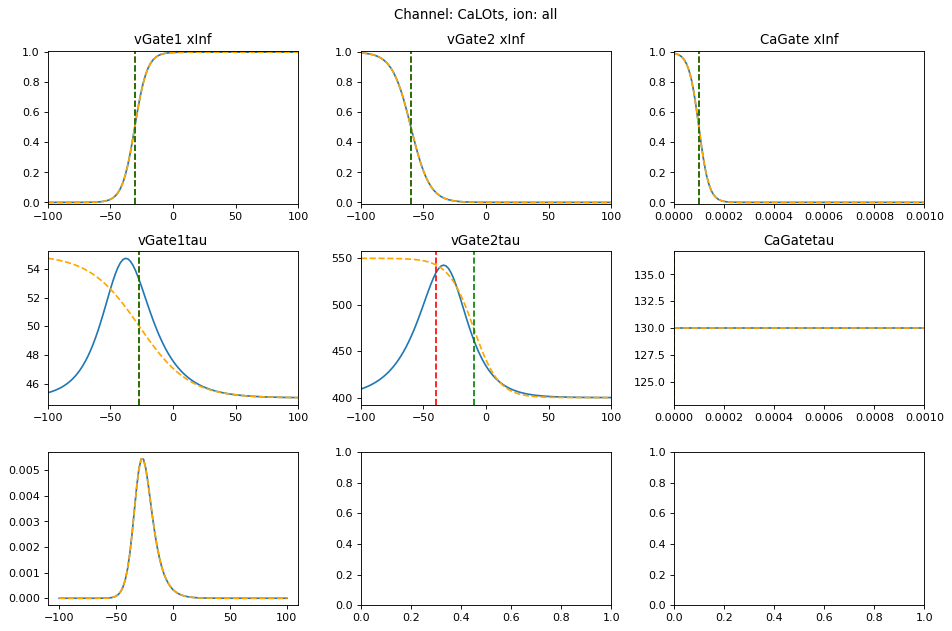

In [43]:
channelToChange = "CaLOts"
# translatedCurrents[channelToChange]["gates"]["vGate1"]["tau1"] = 3
# translatedCurrents[channelToChange]["gates"]["vGate1"]["th"] = -43
# translatedCurrents[channelToChange]["gates"]["vGate1"]["tkInv"] = -1/7

translatedCurrents[channelToChange]["gates"]["vGate2"]["tau1"] = 150
translatedCurrents[channelToChange]["gates"]["vGate2"]["th"] = -10
translatedCurrents[channelToChange]["gates"]["vGate2"]["tkInv"] = -1/10

fig,ax = plt.subplots(3,3,figsize=(12,8), dpi=80)
fig.suptitle(f"Channel: {channelToChange}, ion: {channel['ion']}")
examineChannelOtsuka(stnCurrentDict[channelToChange],ax)
examineChannelNormal(translatedCurrents[channelToChange],ax)

In [44]:
np.save("translatedSTNchannels2.npy",translatedCurrents)